# Simulating 10 haplotypes across 100 bp

In [3]:
from pathlib import Path

import msprime
import numpy as np

num_individuals = 5
sequence_length = 100
population_size = 10_000
recombination_rate = 5e-8
mutation_rate = 1e-6
ancestry_seed = 42
mutation_seed = 43
vcf_path = Path("simulated.vcf")

In [4]:
ancestry = msprime.sim_ancestry(
    samples=num_individuals, ploidy=2, sequence_length=sequence_length,
    population_size=population_size, recombination_rate=recombination_rate,
    model="smc_prime", discrete_genome=False, random_seed=ancestry_seed,
)
ts = msprime.sim_mutations(
    ancestry, rate=mutation_rate, model="jc69",
    discrete_genome=True, random_seed=mutation_seed,
)
print(f"{ts.num_samples} haplotypes, {ts.num_trees} local trees, {ts.num_sites} mutated sites")

10 haplotypes, 3 local trees, 7 mutated sites


In [5]:
names = [f"spl{i}" for i in range(num_individuals)]
with vcf_path.open("w") as out:
    ts.write_vcf(out, contig_id="1", individual_names=names,
                 position_transform=lambda positions: np.minimum(np.asarray(positions, dtype=int) + 1, sequence_length))

lines = vcf_path.read_text().splitlines()
header = next(line for line in lines if line.startswith("#CHROM"))
records = [line.split("\t") for line in lines if not line.startswith("#")]
assert header.split("\t")[9:] == names
assert len(records) == ts.num_sites
for variant, fields in zip(ts.variants(), records):
    assert int(fields[1]) == int(variant.site.position) + 1
    calls = [int(a) for gt in fields[9:] for a in gt.split("|")]
    np.testing.assert_array_equal(calls, variant.genotypes)

print(header)
for record in records[:10]:
    print("\t".join(record))

#CHROM	POS	ID	REF	ALT	QUAL	FILTER	INFO	FORMAT	spl0	spl1	spl2	spl3	spl4
1	38	0	C	T	.	PASS	.	GT	1|1	0|1	1|1	1|0	1|1
1	45	1	T	C	.	PASS	.	GT	1|0	0|1	0|0	0|0	1|1
1	46	2	C	G	.	PASS	.	GT	0|0	1|0	0|0	0|1	0|0
1	60	3	G	A	.	PASS	.	GT	0|0	0|0	1|1	0|0	0|0
1	67	4	A	C	.	PASS	.	GT	0|0	1|0	0|0	0|0	0|0
1	85	5	T	A	.	PASS	.	GT	0|1	0|0	1|1	1|0	0|0
1	99	6	C	T	.	PASS	.	GT	1|0	0|1	0|0	0|0	1|1


In [6]:
# Play one time slot per base and one pitch per phased haplotype.
from IPython.display import Audio

sample_rate = 16000
seconds_per_base = 0.1
frames = round(sample_rate * seconds_per_base)
t = np.arange(frames) / sample_rate

# Assign successive white keys starting at C4, in VCF haplotype order.
h = np.arange(2 * len(names))
major_scale = np.array([0, 2, 4, 5, 7, 9, 11])
midi = 60 + 12 * (h // 7) + major_scale[h % 7]
frequencies = 440 * 2 ** ((midi - 69) / 12)
envelope = np.hanning(frames)
notes = np.sin(2 * np.pi * frequencies[:, None] * t) * envelope

audio_slots = np.zeros((sequence_length, frames))
for fields in records:
    position = int(fields[1])
    carriers = [int(a) > 0 for gt in fields[9:] for a in gt.split("|")]
    audio_slots[position - 1] = notes[carriers].sum(axis=0)

waveform = audio_slots.ravel()
peak = np.max(np.abs(waveform))
audio_player = Audio(0.9 * waveform / max(peak, 1), rate=sample_rate, normalize=False)
Path("genotype_chords.wav").write_bytes(audio_player.data)
audio_player

1	38	0	C	T	.	PASS	.	GT	1|1	0|1	1|1	1|0	1|1
1	45	1	T	C	.	PASS	.	GT	1|0	0|1	0|0	0|0	1|1
1	46	2	C	G	.	PASS	.	GT	0|0	1|0	0|0	0|1	0|0
1	60	3	G	A	.	PASS	.	GT	0|0	0|0	1|1	0|0	0|0
1	67	4	A	C	.	PASS	.	GT	0|0	1|0	0|0	0|0	0|0
1	85	5	T	A	.	PASS	.	GT	0|1	0|0	1|1	1|0	0|0
1	99	6	C	T	.	PASS	.	GT	1|0	0|1	0|0	0|0	1|1


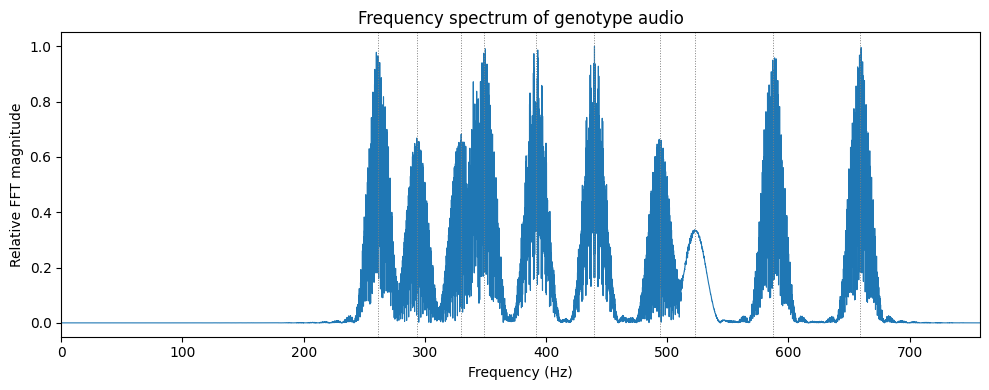

In [7]:

for record in records:
    print("\t".join(record))

# Fourier spectrum of the complete genotype audio.
import matplotlib.pyplot as plt

audio_fft = np.fft.rfft(waveform)
fft_hz = np.fft.rfftfreq(waveform.size, d=1 / sample_rate)
magnitude = np.abs(audio_fft)
relative_magnitude = magnitude / (magnitude.max() or 1)

fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(fft_hz, relative_magnitude, linewidth=0.8)
ax.set(xlim=(0, frequencies.max() * 1.15), xlabel="Frequency (Hz)",
       ylabel="Relative FFT magnitude", title="Frequency spectrum of genotype audio")
for pitch in frequencies:
    ax.axvline(pitch, color="gray", linestyle=":", linewidth=0.7)
plt.tight_layout()
plt.show()

1	38	0	C	T	.	PASS	.	GT	1|1	0|1	1|1	1|0	1|1
1	45	1	T	C	.	PASS	.	GT	1|0	0|1	0|0	0|0	1|1
1	46	2	C	G	.	PASS	.	GT	0|0	1|0	0|0	0|1	0|0
1	60	3	G	A	.	PASS	.	GT	0|0	0|0	1|1	0|0	0|0
1	67	4	A	C	.	PASS	.	GT	0|0	1|0	0|0	0|0	0|0
1	85	5	T	A	.	PASS	.	GT	0|1	0|0	1|1	1|0	0|0
1	99	6	C	T	.	PASS	.	GT	1|0	0|1	0|0	0|0	1|1


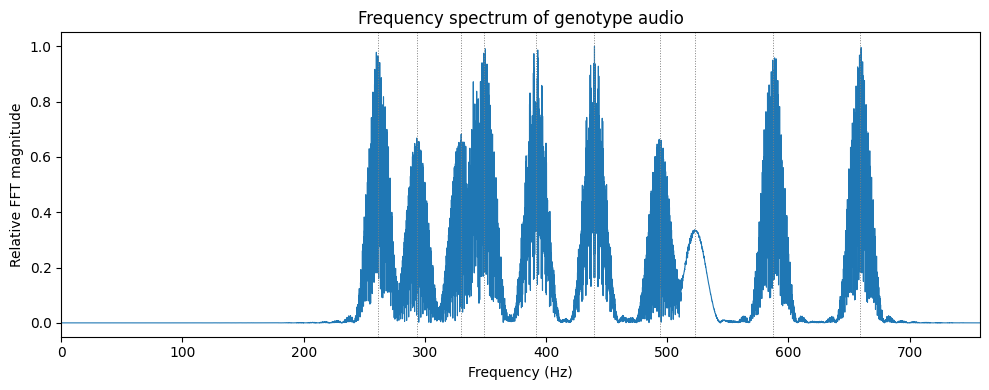

In [8]:

for record in records:
    print("\t".join(record))

# Fourier spectrum of the complete genotype audio.
import matplotlib.pyplot as plt

audio_fft = np.fft.rfft(waveform)
fft_hz = np.fft.rfftfreq(waveform.size, d=1 / sample_rate)
magnitude = np.abs(audio_fft)
relative_magnitude = magnitude / (magnitude.max() or 1)

fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(fft_hz, relative_magnitude, linewidth=0.8)
ax.set(xlim=(0, frequencies.max() * 1.15), xlabel="Frequency (Hz)",
       ylabel="Relative FFT magnitude", title="Frequency spectrum of genotype audio")
for pitch in frequencies:
    ax.axvline(pitch, color="gray", linestyle=":", linewidth=0.7)
plt.tight_layout()
plt.show()

1	38	0	C	T	.	PASS	.	GT	1|1	0|1	1|1	1|0	1|1
1	45	1	T	C	.	PASS	.	GT	1|0	0|1	0|0	0|0	1|1
1	46	2	C	G	.	PASS	.	GT	0|0	1|0	0|0	0|1	0|0
1	60	3	G	A	.	PASS	.	GT	0|0	0|0	1|1	0|0	0|0
1	67	4	A	C	.	PASS	.	GT	0|0	1|0	0|0	0|0	0|0
1	85	5	T	A	.	PASS	.	GT	0|1	0|0	1|1	1|0	0|0
1	99	6	C	T	.	PASS	.	GT	1|0	0|1	0|0	0|0	1|1


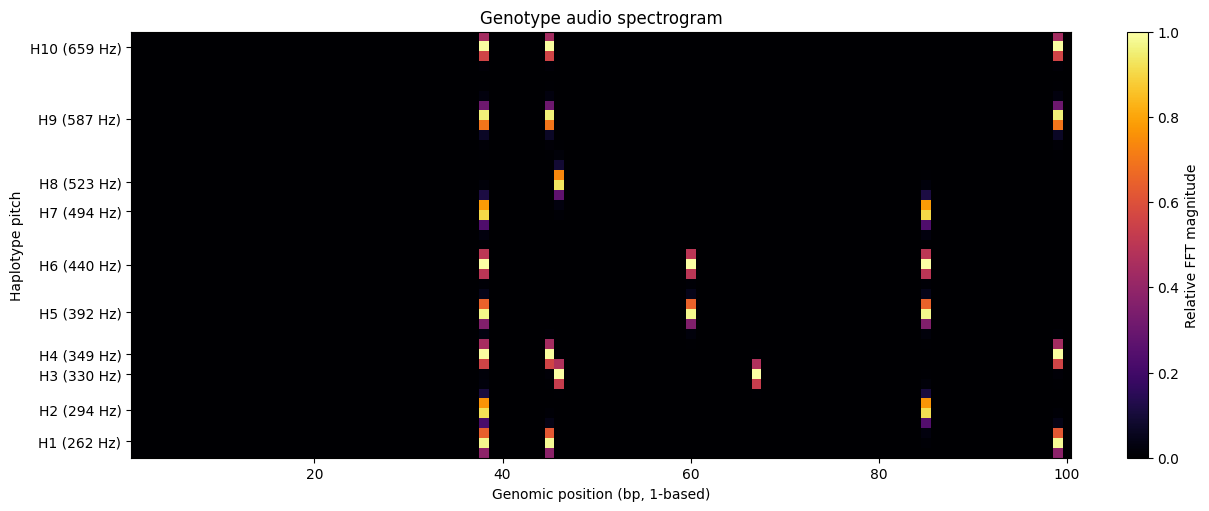

In [11]:

for record in records:
    print("\t".join(record))

# Each Fourier window spans one base in the recording.
import matplotlib.pyplot as plt

slot_hz = np.fft.rfftfreq(frames, d=1 / sample_rate)
band = (slot_hz >= frequencies.min() - 20) & (slot_hz <= frequencies.max() + 20)
spectrum = np.abs(np.fft.rfft(waveform.reshape(-1, frames), axis=1)[:, band])
half_bin = sample_rate / frames / 2
extent = (0.5, sequence_length + 0.5, slot_hz[band][0] - half_bin, slot_hz[band][-1] + half_bin)

fig, ax = plt.subplots(figsize=(12, 5), constrained_layout=True)
im = ax.imshow(spectrum.T / (spectrum.max() or 1), origin="lower", aspect="auto",
               interpolation="nearest", extent=extent, cmap="inferno")
ax.set_yticks(frequencies, labels=[f"H{i} ({hz:.0f} Hz)" for i, hz in enumerate(frequencies, 1)])
ax.set(xlabel="Genomic position (bp, 1-based)", ylabel="Haplotype pitch",
       title="Genotype audio spectrogram")
fig.colorbar(im, ax=ax, label="Relative FFT magnitude")
plt.show()

1	38	0	C	T	.	PASS	.	GT	1|1	0|1	1|1	1|0	1|1
1	45	1	T	C	.	PASS	.	GT	1|0	0|1	0|0	0|0	1|1
1	46	2	C	G	.	PASS	.	GT	0|0	1|0	0|0	0|1	0|0
1	60	3	G	A	.	PASS	.	GT	0|0	0|0	1|1	0|0	0|0
1	67	4	A	C	.	PASS	.	GT	0|0	1|0	0|0	0|0	0|0
1	85	5	T	A	.	PASS	.	GT	0|1	0|0	1|1	1|0	0|0
1	99	6	C	T	.	PASS	.	GT	1|0	0|1	0|0	0|0	1|1


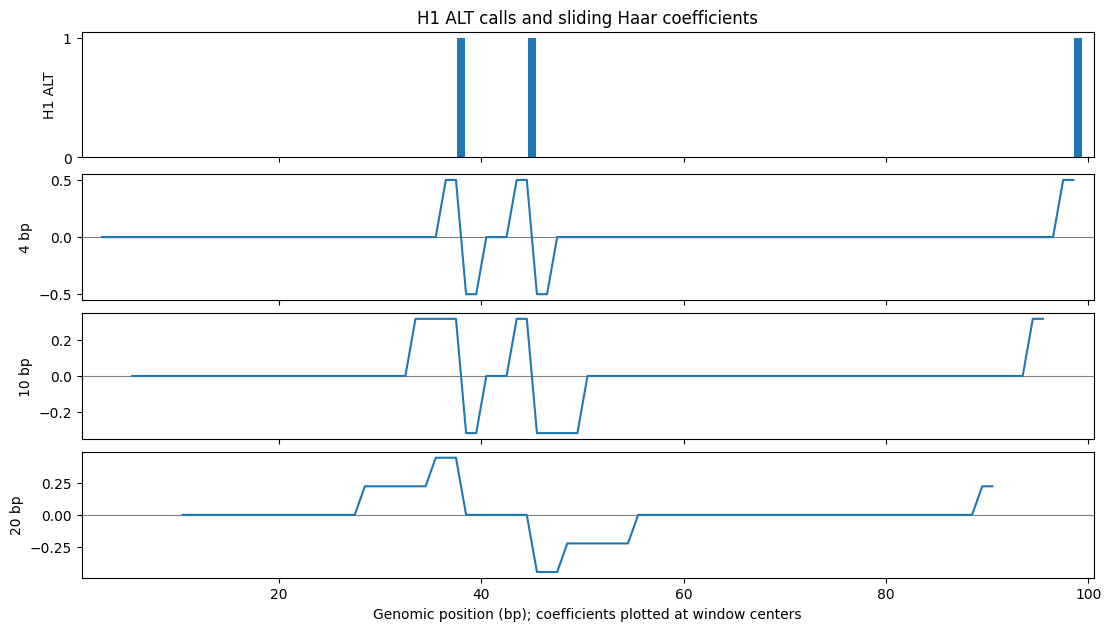

Bases 81–100: left ALT count = 0, right ALT count = 1, Haar coefficient = +0.224


In [12]:
# Sliding Haar wavelet on H1 (the first phased haplotype in the VCF).

for record in records:
    print("\t".join(record))

import matplotlib.pyplot as plt
import numpy as np
h1_alt = np.zeros(sequence_length, dtype=int)
for fields in records:
    position = int(fields[1])
    h1_alt[position - 1] = int(fields[9].split("|")[0]) > 0

widths = [w for w in (4, 10, 20) if w <= sequence_length]
fig, axes = plt.subplots(1 + len(widths), 1, sharex=True, squeeze=False,
                         figsize=(11, 2 + 1.4 * len(widths)), constrained_layout=True)
axes = axes[:, 0]
axes[0].bar(np.arange(1, sequence_length + 1), h1_alt, width=0.8)
axes[0].set(title="H1 ALT calls and sliding Haar coefficients", ylabel="H1 ALT", yticks=[0, 1])

haar_coefficients = {}
for ax, width in zip(axes[1:], widths):
    half = width // 2
    # Positive when more ALT calls fall in the right half. Unit-norm Haar weights.
    weights = np.r_[-np.ones(half), np.ones(half)] / np.sqrt(width)
    coefficients = np.correlate(h1_alt, weights, mode="valid")
    haar_coefficients[width] = coefficients
    centers = np.arange(len(coefficients)) + (width + 1) / 2
    ax.axhline(0, color="gray", linewidth=0.8)
    ax.plot(centers, coefficients)
    ax.set_ylabel(f"{width} bp")
axes[-1].set(xlabel="Genomic position (bp); coefficients plotted at window centers",
             xlim=(0.5, sequence_length + 0.5))
plt.show()

if sequence_length >= 100:
    print(f"Bases 81–100: left ALT count = {h1_alt[80:90].sum()}, "
          f"right ALT count = {h1_alt[90:100].sum()}, "
          f"Haar coefficient = {haar_coefficients[20][80]:+.3f}")